# PCR vs PLS regression — *Communities and Crime* data

**Goal of the project.** Explain, for a non-expert reader, what Partial Least Squares (PLS) regression does and how it differs from
Principal Components Regression (PCR), using one real data set with many correlated predictors.

**The one-sentence answer we will illustrate.** Both methods replace the 100 original predictors by a few *components*
(linear combinations of the predictors) and regress the response on them. **PCR builds its components by looking only at $X$**
(directions of maximum variance), **PLS builds them by looking at $X$ *and* $y$** (directions of maximum covariance with the response).

**Code conventions.** The code follows the course notebooks (Chapter 1: PCA by eigen-decomposition of the correlation matrix;
Chapter 2: standardized $X$, centered $Y$, PCR written with the SVD of $X$) and the PLS algorithm of the slides by
G. Sanchez. scikit-learn is only used to *check* that our hand-written code gives the right numbers.

### Roadmap

| Part | Sections | What it does |
|---|---|---|
| **I. Data** | 1–4 | Load and clean the data; show that the predictors are strongly correlated (why PCR/PLS make sense here) |
| **II. The two methods, step by step** | 5–8 | Standardize; PCR with the SVD (course formulas); PLS with the slides' algorithm; compare what each one maximises |
| **III. Honest comparison of predictions** | 9–12 | Explain the cross-validation by **groups of states**; choose the number of components; measure the error on states never seen |
| **IV. When and why they differ** | 13–14 | Effect of the sample size; interpretation of components and coefficients |
| **V. Robustness** | 15–16 | Without the race variables; 20 different splits of the states |
| **VI. Conclusion** | 17–18 | Summary table, take-aways and limits |

---
# Part I — Data

## 1. Libraries and settings

Same libraries as in the course notebooks.

In [2]:
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from numpy.linalg import eig, inv, svd

from sklearn.model_selection import GroupKFold, GroupShuffleSplit
from sklearn.cross_decomposition import PLSRegression   # only used to CHECK our own PLS code
from sklearn.decomposition import PCA                    # only used to CHECK our own PCR code
from sklearn.linear_model import LinearRegression        # only used to CHECK our own PCR code

warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"] = [10, 5]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})

# Colours used in every figure
C_PCR, C_PLS, C_OLS, C_MEAN = "#1f77b4", "#e07b00", "#8c564b", "#888888"

SEED = 0
N_FOLDS = 5                           # 5 folds of STATES (see Section 9)

## 2. Loading the data

**Source.** UCI Machine Learning Repository, *Communities and Crime* (Redmond & Baveja, 2002), licence CC BY 4.0.
It combines the 1990 US Census, the 1990 LEMAS police survey and the 1995 FBI crime statistics.

- **1 994 communities** (cities/towns) in **46 states**.
- **128 columns**: 5 identifiers, 122 socio-economic predictors, and the response `ViolentCrimesPerPop`
  (violent crimes per 100 000 inhabitants).
- Every numeric variable has already been **normalized to [0, 1]** by the authors. So a value of 0.5 means "in the middle of the range of
  that variable", not "50 %".
- Missing values are coded `?`.

The two files `communities.data` (the values) and `communities.names` (the description, from which we read the column names)
are in the `datas/` folder of the repository. On Google Colab, upload them to `/content` (folder icon on the left → Upload).

In [3]:
# The two files are looked for in: datas/ (copy of the GitHub repo), the notebook's folder, /content (Google Colab)
FOLDERS = [Path("datas"), Path("."), Path("/content")]
DATA_DIR = next((d for d in FOLDERS if (d / "communities.data").exists() and (d / "communities.names").exists()), None)
if DATA_DIR is None:
    raise FileNotFoundError("communities.data and communities.names not found. Run the notebook from the repo "
                            "(files in datas/) or, on Colab, upload them to /content.")
DATA_FILE = DATA_DIR / "communities.data"
NAMES_FILE = DATA_DIR / "communities.names"
print("Data read from:", DATA_DIR.resolve())

# Column names: the .names file contains one line '@attribute <name> <type>' per column
names = [m.group(1) for line in NAMES_FILE.read_text(errors="ignore").splitlines()
         if (m := re.match(r"@attribute\s+(\S+)", line))]

df = pd.read_csv(DATA_FILE, header=None, na_values="?")
df.columns = names

print("Shape of the data:", df.shape)
df.head()

Data read from: C:\Users\arcad\Desktop\PROJECTS\AUTOMATIC SELECTION MODEL\Small project\automatic-model-selection\datas
Shape of the data: (1994, 128)


,state,county,community,communityname,fold,population,householdsize,racepctblack,racePctWhite,racePctAsian,...,LandArea,PopDens,PctUsePubTrans,PolicCars,PolicOperBudg,LemasPctPolicOnPatr,LemasGangUnitDeploy,LemasPctOfficDrugUn,PolicBudgPerPop,ViolentCrimesPerPop
0,8,NaN,NaN,Lakewoodcity,1,0.19,0.33,0.02,0.90,0.12,...,0.12,0.26,0.20,0.06,0.04,0.9,0.5,0.32,0.14,0.20
1,53,NaN,NaN,Tukwilacity,1,0.00,0.16,0.12,0.74,0.45,...,0.02,0.12,0.45,NaN,NaN,NaN,NaN,0.00,NaN,0.67
2,24,NaN,NaN,Aberdeentown,1,0.00,0.42,0.49,0.56,0.17,...,0.01,0.21,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.43
3,34,5.0,81440.0,Willingborotownship,1,0.04,0.77,1.00,0.08,0.12,...,0.02,0.39,0.28,NaN,NaN,NaN,NaN,0.00,NaN,0.12
4,42,95.0,6096.0,Bethlehemtownship,1,0.01,0.55,0.02,0.95,0.09,...,0.04,0.09,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.03


## 3. Cleaning

Three decisions, each explained:

1. **Drop the 5 identifiers** (`state`, `county`, `community`, `communityname`, `fold`): they are not predictors.
   We keep `state` aside in a vector `groups`: it will be used to split the data **by state** (Section 9).
2. **Drop the 22 police variables (LEMAS)**: they are missing for 1 675 of the 1 994 communities (84 %).
   Keeping them would force us to throw away 84 % of the rows.
3. **One remaining missing value** (`OtherPerCap`, one community). It is replaced by the median of the variable.
   In Parts III–V this is done *inside each training sample* (the median is computed without looking at the test data).

We end up with **1 994 communities × 100 predictors**.

In [4]:
ID_COLS = ["state", "county", "community", "communityname", "fold"]
TARGET = "ViolentCrimesPerPop"

groups = df["state"].to_numpy()                 # state of each community (used for the grouped cross-validation)
Y = df[TARGET]
X_all = df.drop(columns=ID_COLS + [TARGET])

share_missing = X_all.isna().mean()
lemas_cols = share_missing[share_missing > 0.5].index.tolist()
X = X_all.drop(columns=lemas_cols)
FEATURES = X.columns.tolist()

print(f"Police (LEMAS) variables dropped: {len(lemas_cols)}")
print(f"Remaining missing values: {int(X.isna().sum().sum())} (in {X.columns[X.isna().any()].tolist()})")
print(f"Final data: n = {X.shape[0]} communities, p = {X.shape[1]} predictors, {len(np.unique(groups))} states")

Police (LEMAS) variables dropped: 22
Remaining missing values: 1 (in ['OtherPerCap'])
Final data: n = 1994 communities, p = 100 predictors, 46 states


count    1994.000
mean        0.238
std         0.233
min         0.000
25%         0.070
50%         0.150
75%         0.330
max         1.000
Name: ViolentCrimesPerPop, dtype: float64


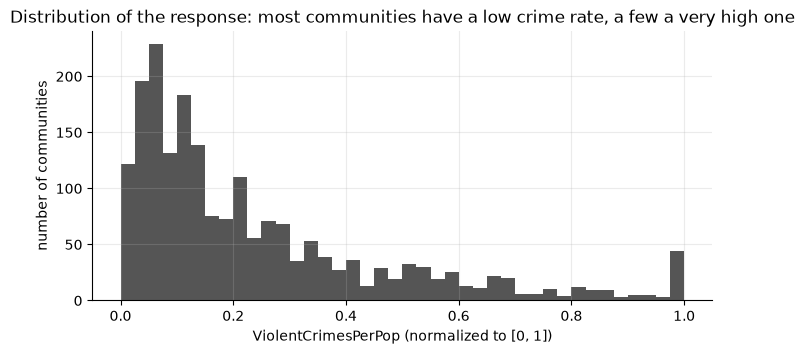

In [5]:
# The response variable
print(Y.describe().round(3))

plt.figure(figsize=(8, 3.5))
plt.hist(Y, bins=40, color="#555")
plt.xlabel("ViolentCrimesPerPop (normalized to [0, 1])"); plt.ylabel("number of communities")
plt.title("Distribution of the response: most communities have a low crime rate, a few a very high one")
plt.show()

## 4. Correlation of the predictors

PCR and PLS are useful when the predictors are **many and redundant** (multicollinearity). Then OLS coefficients become unstable.

To make sure it is relevant here we check : 
- **eigen-decomposition of the correlation matrix** 
- **eigenvalues sorted in decreasing order** 
- **proportion of variance explained by each principal component**

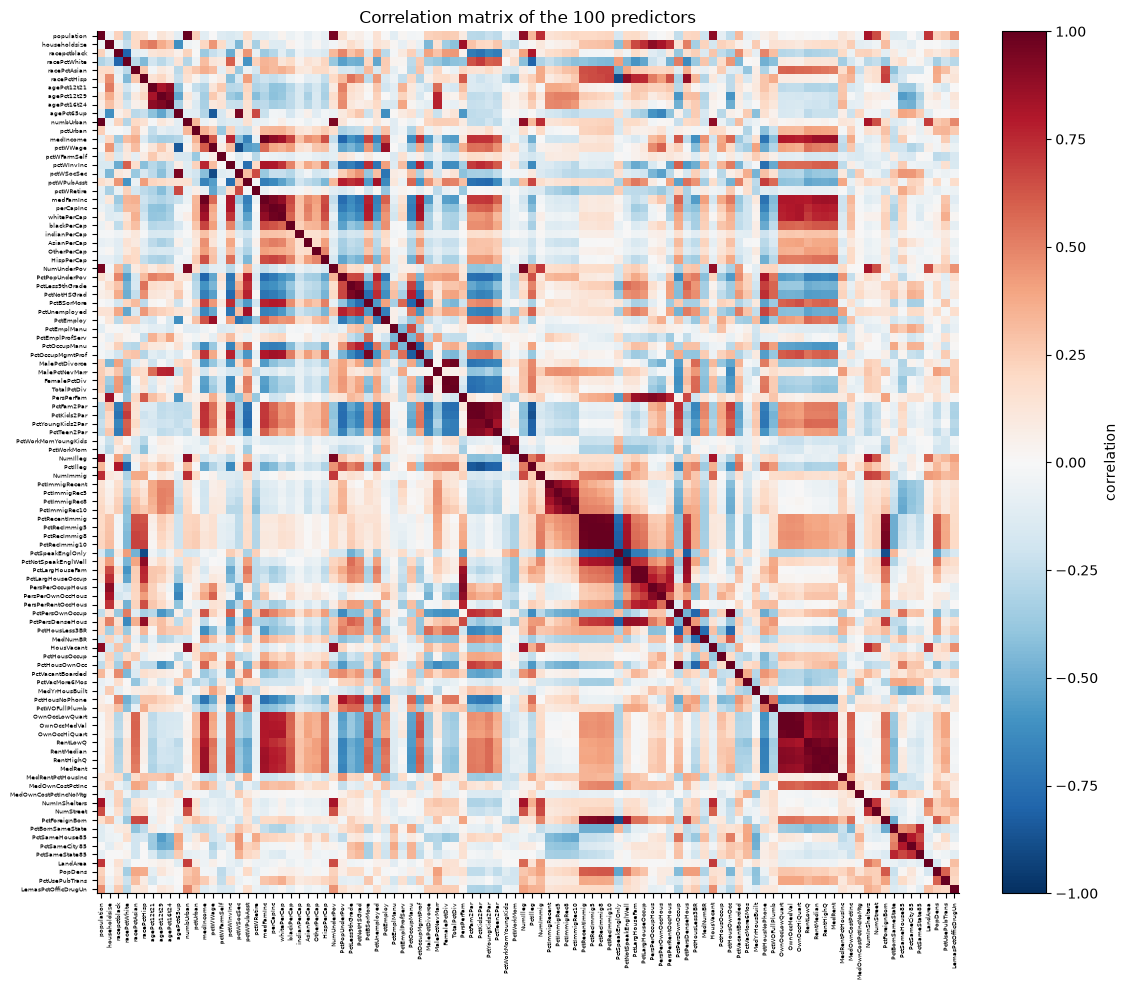

Pairs with |correlation| > 0.8: 127 of the 4950 pairs (2.6%)


In [11]:
# We replace the single missing value by the median for the descriptive part
X_filled = X.fillna(X.median())
n, p = X_filled.shape

# Correlation matrix
corr_matrix = X_filled.corr()

# Visual display of the correlation matrix
fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(corr_matrix.values, cmap="RdBu_r", vmin=-1, vmax=1)   # red = positive, blue = negative
ax.set_xticks(range(len(FEATURES))); ax.set_yticks(range(len(FEATURES)))
ax.set_xticklabels(FEATURES, rotation=90, fontsize=4)
ax.set_yticklabels(FEATURES, fontsize=4)
ax.grid(False)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="correlation")
ax.set_title("Correlation matrix of the 100 predictors")
plt.tight_layout()
plt.show()

# Number of predictor pairs with a strong correlation
iu = np.triu_indices_from(corr_matrix, k=1)
strong = np.abs(corr_matrix.values[iu]) > 0.8
print(f"Pairs with |correlation| > 0.8: {strong.sum()} of the {len(iu[0])} pairs ({strong.mean():.1%})")

In [12]:
# Computation of eigenvalues and eigenvectors, then sort them (as in the course)
l, e = eig(corr_matrix)
idx = l.real.argsort()[::-1]
l, e = l.real[idx], e.real[:, idx]

# Computation of the proportion of variance explained by each principal component
Proportion_var_expl_PC = l / sum(l)
cum_var = np.cumsum(Proportion_var_expl_PC)

print("Proportion of variance explained by PC1 to PC5:", np.round(Proportion_var_expl_PC[:5], 3))
for q in (0.80, 0.90, 0.95):
    print(f"Number of components needed for {q:.0%} of the variance: {np.searchsorted(cum_var, q) + 1} (out of p = {p})")
print(f"Largest eigenvalue = {l[0]:.2f} | smallest eigenvalue = {l[-1]:.5f} | condition number sqrt(l_max/l_min) = {np.sqrt(l[0]/l[-1]):.0f}")

Proportion of variance explained by PC1 to PC5: [0.252 0.168 0.093 0.076 0.056]
Number of components needed for 80% of the variance: 11 (out of p = 100)
Number of components needed for 90% of the variance: 23 (out of p = 100)
Number of components needed for 95% of the variance: 35 (out of p = 100)
Largest eigenvalue = 25.18 | smallest eigenvalue = 0.00063 | condition number sqrt(l_max/l_min) = 200


---
# Part II — PCR and PLS

In this part we fit the methods on all 1 994 communities to understand *how they work*.

## 5. Standardization

We standardize X (each column to mean 0 and variance 1) and center Y (mean 0).

In [14]:
# Centered Y
mean_Y = Y.mean()
centered_Y = (Y - mean_Y).to_numpy()

# Standardized X 
mean_X = X_filled.mean()
std_X = X_filled.std(ddof=0)
standardized_X = ((X_filled - mean_X) / std_X).to_numpy()

print("Means of the standardized X (should be 0):", np.abs(standardized_X.mean(0)).max().round(12))
print("Variances of the standardized X (should be 1):", np.round(standardized_X.var(0)[:5], 6), "...")
print("X'X/n equals the correlation matrix:", np.allclose(standardized_X.T @ standardized_X / n, corr_matrix.values))

Means of the standardized X (should be 0): 0.0
Variances of the standardized X (should be 1): [1. 1. 1. 1. 1.] ...
X'X/n equals the correlation matrix: True


## 6. PCR — Principal Components Regression

There are **two stages**:
1. **PCA on $X$ only** — find the directions in which the communities differ the most (maximum variance of $X$). The response is *not* used.
2. **OLS of $y$ on the first $k$ principal components.**



### 6.1 The SVD of $X$ and its link with the PCA of Section 4